# 스마트 트랩 EDA (가상 시나리오 데이터셋)

> **주의:** 이 노트북의 데이터는 모두 **가상(시뮬레이션)** 입니다. 감지·포획 수치는 현장 측정값이 아니며, 포획은 실제 포획 실적이 아닙니다.
> 여기서 확인하는 것은 "분석 파이프라인과 지표가 설계한 위치 유형을 구분해 내는가"이지, 실제 현장 성능이 아닙니다.

목적: 위치 추천 알고리즘에 쓸 변수를 고른다.

In [1]:
import sys
sys.path.insert(0, "..")  # 프로젝트 루트를 import 경로에 추가

import warnings
import pandas as pd
import matplotlib.pyplot as plt

from src.data_analysis import (setup_style, plot_location_comparison, plot_trap_location_conversion,
                               plot_hourly_profile, plot_env_vs_detection, quality_report)
from src.metrics import aggregate_performance
from src.preprocessing import load_trap_day_summary

setup_style()
D = "../data/synthetic/scenario/"
summary = load_trap_day_summary(D + "trap_day_summary.csv")
events = pd.read_csv(D + "detection_events.csv")
print("일 집계:", summary.shape, "| 이벤트:", events.shape)
summary.head()

일 집계: (129, 14) | 이벤트: (802, 7)


,trap_id,location_id,date,operating_hours,rat_detections,non_rat_detections,unclassified_detections,avg_temperature_c,avg_humidity_pct,avg_tvoc_ppb,avg_eco2_ppm,sim_captures,detection_source,capture_source
0,TRAP-01,LOC-A,2026-11-09,24,4,1,0,20.85,49.87,187.58,577.55,1,synthetic,synthetic
1,TRAP-02,LOC-B,2026-11-09,24,10,2,0,20.92,50.93,164.25,565.50,1,synthetic,synthetic
2,TRAP-03,LOC-C,2026-11-09,24,1,0,0,21.08,50.05,180.91,533.17,0,synthetic,synthetic
3,TRAP-05,LOC-B,2026-11-09,24,5,0,0,20.97,50.12,181.35,529.26,1,synthetic,synthetic
4,TRAP-06,LOC-F,2026-11-09,24,6,1,0,20.98,50.55,173.96,575.96,0,synthetic,synthetic


## 1. 데이터 품질 확인

In [2]:
quality_report(summary, events)

{'trap_day_rows': 129,
 'zero_operating_rows': 1,
 'env_missing_rate': {'avg_temperature_c': 0.008,
  'avg_humidity_pct': 0.008,
  'avg_tvoc_ppb': 0.008,
  'avg_eco2_ppm': 0.008},
 'event_count': 802,
 'unclassified_rate': 0.042,
 'non_rat_rate_of_classified': 0.132,
 'duplicate_event_ids': 0}

- 센서 평균 결측은 0.8%로, 작동 0시간인 날(1일)에서만 발생했습니다. 0으로 채우지 않고 결측으로 두었습니다.
- 분류 실패(`null`) 이벤트는 4.2%입니다. 이 이벤트는 쥐 감지 수에도 포획 계산에도 넣지 않습니다.
- 중복 이벤트 ID는 없습니다.

## 2. 위치별 감지와 가상 포획 성과

,location_id,observed_days,operating_hours,rat_detections,detection_rate,sim_captures,sim_conversion,is_insufficient
0,LOC-A,55,1274,351,0.276,104,0.296,False
1,LOC-B,28,652,182,0.279,8,0.044,False
2,LOC-C,28,640,35,0.055,6,0.171,False
3,LOC-D,3,72,14,0.194,5,0.357,True
4,LOC-F,14,329,85,0.258,3,0.035,False


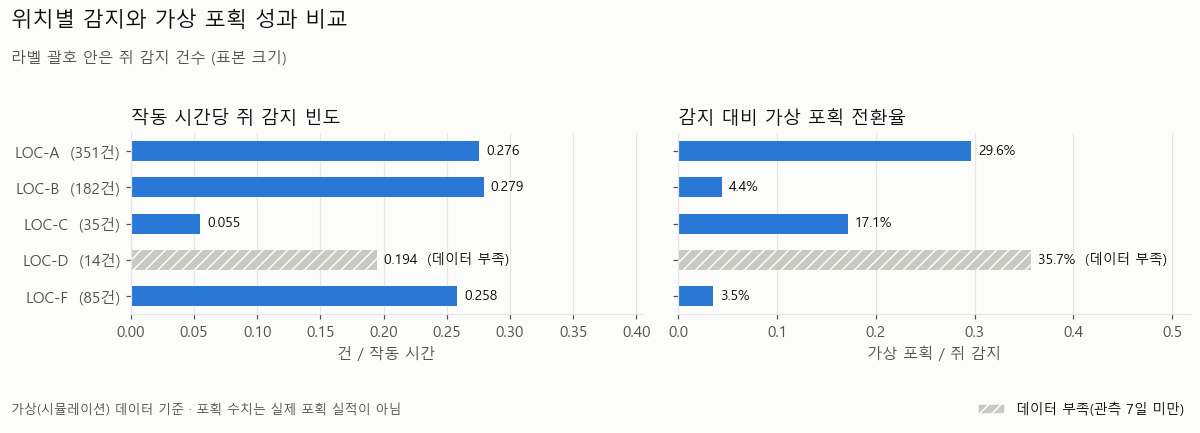

In [3]:
by_location = aggregate_performance(summary)
cols = ["location_id", "observed_days", "operating_hours", "rat_detections", "detection_rate",
        "sim_captures", "sim_conversion", "is_insufficient"]
display(by_location[cols].round(3))
fig = plot_location_comparison(by_location); plt.show()

**관찰**
- LOC-A, LOC-B, LOC-F는 감지 빈도가 0.26~0.28건/시간으로 비슷합니다. **감지 횟수만 보면 B와 F도 좋은 위치로 판단**하게 됩니다.
- 하지만 전환율은 A 29.6%, B 4.4%, F 3.5%로 크게 갈립니다. 감지 횟수만으로 위치를 판단하면 안 되는 이유입니다.
- LOC-C는 감지 자체가 적습니다(0.055건/시간, 35건).
- LOC-D는 관측 3일(72시간)뿐이라 **데이터 부족**으로 표시했습니다. 전환율 35.7%는 14건 중 5건이라 신뢰할 수 없습니다.
- LOC-C 전환율(17.1%)도 감지가 35건뿐이라 불확실성이 큽니다. 표본 크기(감지 건수)를 함께 봐야 합니다.

## 3. 트랩 × 위치별 전환율: 위치 문제와 장치 문제 구분

,trap_id,location_id,observed_days,rat_detections,sim_captures,sim_conversion,is_insufficient
0,TRAP-01,LOC-A,27,176,70,0.398,False
1,TRAP-02,LOC-A,14,91,31,0.341,False
2,TRAP-02,LOC-B,14,88,2,0.023,False
3,TRAP-03,LOC-C,28,35,6,0.171,False
4,TRAP-04,LOC-D,3,14,5,0.357,True
5,TRAP-05,LOC-B,14,94,6,0.064,False
6,TRAP-06,LOC-A,14,84,3,0.036,False
7,TRAP-06,LOC-F,14,85,3,0.035,False


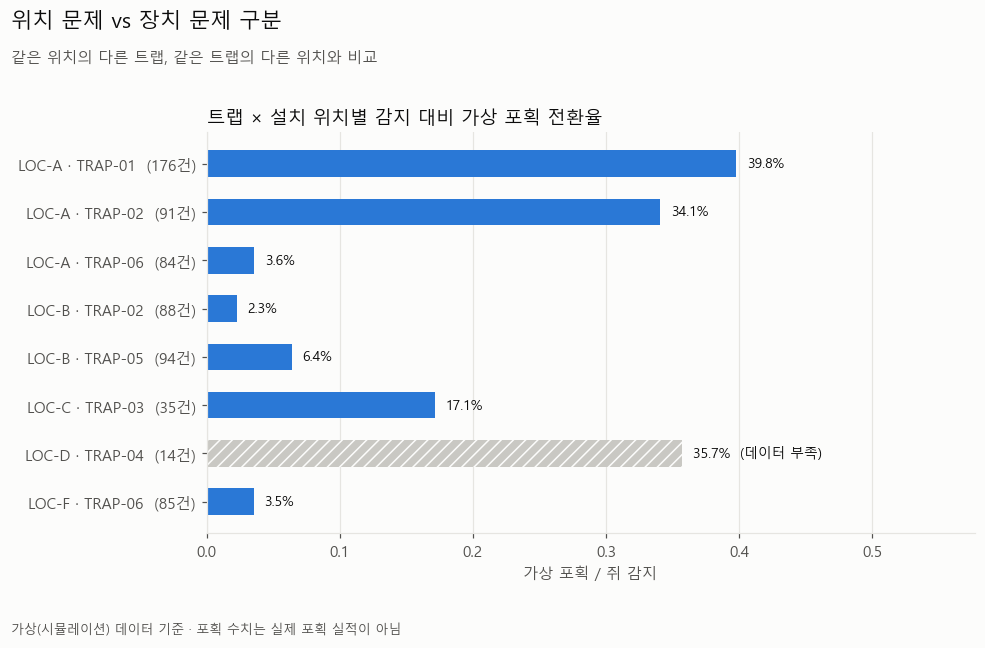

In [4]:
by_trap_loc = aggregate_performance(summary, by=("trap_id", "location_id"))
display(by_trap_loc[["trap_id", "location_id", "observed_days", "rat_detections", "sim_captures",
                     "sim_conversion", "is_insufficient"]].round(3))
fig = plot_trap_location_conversion(by_trap_loc); plt.show()

**관찰**
- **위치 문제 패턴:** TRAP-02는 LOC-B에서 2.3%, LOC-A로 옮기자 34.1%입니다. LOC-B에 있던 TRAP-05도 6.4%로 낮습니다. → 트랩이 아니라 **위치가 문제**.
- **장치 문제 패턴:** TRAP-06은 LOC-F에서 3.5%, LOC-A로 옮겨도 3.6%입니다. 같은 LOC-A의 다른 트랩은 34~40%입니다. → 위치가 아니라 **장치가 문제**.
- **중요한 함정:** 위치 단위 집계에서 LOC-A의 전환율은 29.6%이지만, 이는 정상 트랩(34~40%)과 고장 트랩(3.6%)이 섞인 평균입니다. 위치 평가는 **트랩 단위로 먼저 보고, 장치 문제로 의심되는 트랩의 데이터는 위치 평가에서 분리**해야 합니다.

## 4. 시간대별 감지 분포

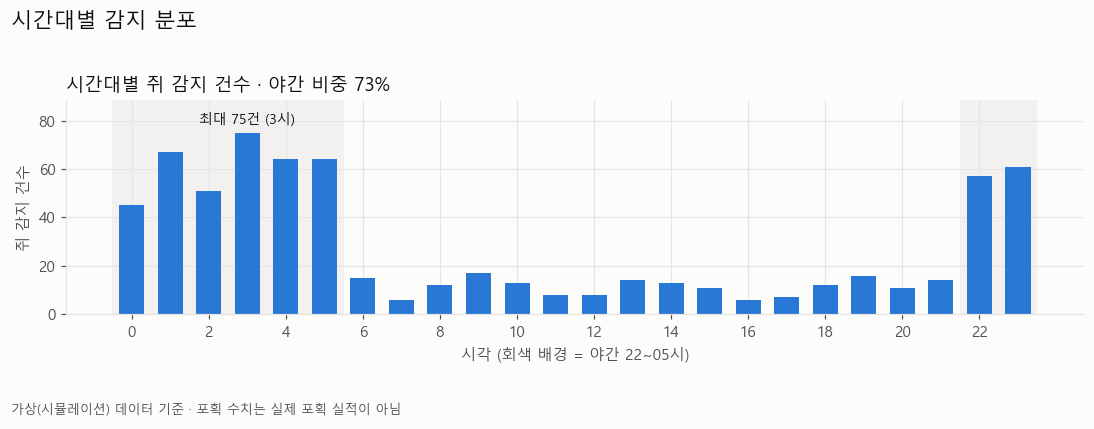

야간(22~05시) 비중: 72.6%


In [5]:
fig, night_share = plot_hourly_profile(events); plt.show()
print(f"야간(22~05시) 비중: {night_share:.1%}")

**관찰**
- 쥐 감지의 약 73%가 야간(22~05시)에 몰립니다(생성 시 가정은 75%).
- 시간대 분포는 이벤트 로그에서만 볼 수 있습니다(일 집계에서는 사라짐).
- 활용: 이후 대시보드에서 시간대별 감지 그래프, 야간 위주 트랩 점검 안내에 쓸 수 있습니다. 위치 점수 자체에는 쓰지 않습니다.

## 5. 환경 조건과 감지의 관계

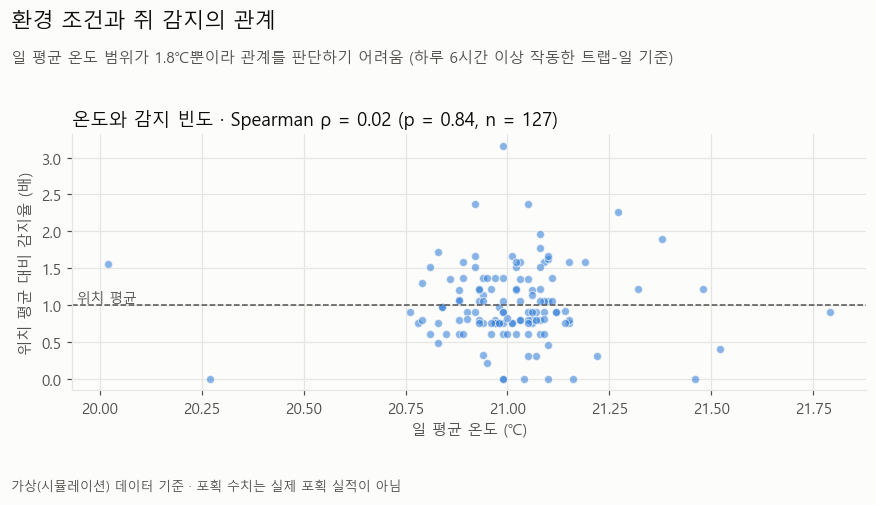

Spearman rho=0.018, p=0.843
일 평균 온도 범위: 19.93 ~ 21.79


In [6]:
fig, rho, p = plot_env_vs_detection(summary); plt.show()
print(f"Spearman rho={rho:.3f}, p={p:.3f}")
print("일 평균 온도 범위:", summary['avg_temperature_c'].min(), "~", summary['avg_temperature_c'].max())

**관찰**
- 온도와 감지율의 Spearman 상관은 거의 0(ρ≈0.02)입니다.
- **다만 이 결과는 "관계가 없다"는 증거가 아닙니다.** 가상 데이터의 일 평균 온도가 20.2~21.8℃로 거의 변하지 않아, 관계를 볼 수 있는 조건이 아닙니다(날짜별 온도 변동을 생성에 넣지 않았음).
- 환경 변수는 실제 데이터가 쌓인 뒤 다시 분석합니다. 지금은 추천 점수에서 제외합니다.

## 6. 위치 추천에 활용할 변수 목록

| 변수 | 수준 | 용도 | 비고 |
|---|---|---|---|
| `detection_rate` (감지 빈도) | 위치, 트랩 | 쥐가 자주 오는 위치인지 | 작동 시간으로 보정 |
| `sim_conversion` (감지 대비 전환율) | **트랩×위치** | 감지가 포획으로 이어지는지 | 가상 데이터 기반 추정치임을 표시 |
| `rat_detections` (감지 건수) | 위치, 트랩 | **표본 크기 = 신뢰도** | 적으면 전환율을 확정하지 않음 |
| `observed_days`, `operating_hours` | 위치, 트랩 | **데이터 부족 판정** (7일/72시간) | D 유형 처리 |
| 같은 트랩의 다른 위치 성과 / 같은 위치의 다른 트랩 성과 | 트랩×위치 | **위치 vs 장치 문제 구분** | 이동 이력이 있을 때만 판단 가능 |
| `non_rat_ratio` | 위치 | 참고용 (분류 결과 기준) | 정답 라벨이 없어 점수에는 쓰지 않음 |
| `unclassified_detections` 비율 | 트랩 | 카메라 품질 이상 신호 | 참고용 |
| 온도/습도/TVOC/eCO2 | 일 | - | 현재 데이터로는 판단 불가, **제외** |

**설계에 반영할 결론**
1. 감지 횟수만으로 점수를 만들지 않는다. 감지 빈도와 전환율을 함께 본다.
2. 전환율은 트랩×위치 단위로 계산하고, 표본이 적으면 확정하지 않는다.
3. 같은 위치의 다른 트랩, 같은 트랩의 다른 위치와 비교해 위치 문제와 장치 문제를 구분한다.
4. 설치 이력이 없는 후보 위치(LOC-E)는 관측값이 없으므로 성과를 예측하지 않고 `new_candidate`로 표시한다.

## 7. 한계
- 모든 수치는 가상 데이터이며 위치별 감지율·포획확률은 설계자가 정한 가정입니다.
- 데이터 부족 기준(7일, 72시간)은 초기값입니다. 이 데이터에서는 D(3일)만 걸러져 기준의 적절성을 검증하지 못했습니다.
- 환경 변수 분석은 가상 데이터의 온도 변동이 없어 수행하지 못했습니다.